---
A Notebook that shows how the physics model/tools work, and makes a series of nice plots

calling GenPaths.py from: .../daaps/pythonModelling/DAAPS_TOOLKIT/GenPaths.py
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/FittingTools
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel
global path variables:
	 PROJECT_PATH =.../.../vera/daaps/pythonModelling/DAAPS_TOOLKIT
	 OPTICS_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA
	 LITERATURE_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/literatureDATA
	 VERA_DATA_PATH =.../.../projects/vera/daaps/veraData
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'name', 'printMembers']


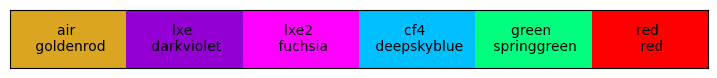

In [2]:
import matplotlib.pyplot as plt
import copy

from DAAPS_TOOLKIT.GenPaths import *

import PDEModel.MathEquations as ME
from PDEModel.OpticsDataLoader import *
import PDEModel.PDEStyle as MS
from PDEModel.PhotonInfo import * # this calls DataLoader when defining init
from PNJunction import * 
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


# rad2deg = 180/np.pi

MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like
ms.SetMPLcolors() # turn off with "off" option

In [3]:
## loading in all data
testVerbose = 1
od_default = OpticsData(verbose = 0) # default loads lithography Si-crystalline and Oxide-UV
p1 = PhotonInfo(wlen = 1000, theta_1=2, dataHelper=od_default)

p1.PrintMaterialInfo();

print("-----------------\ndefault files:")
print(od_default.mPathSi)
print(od_default.mPathSiO2)


-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
-- Material Information: 1000 nm --
nSi: (3.575108+0.0005j)
nOxide: (1.450372881355932+0j)
muSi: 6.283185307179587e-06
muOxide: 0.0
-----------------
default files:
/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opti

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


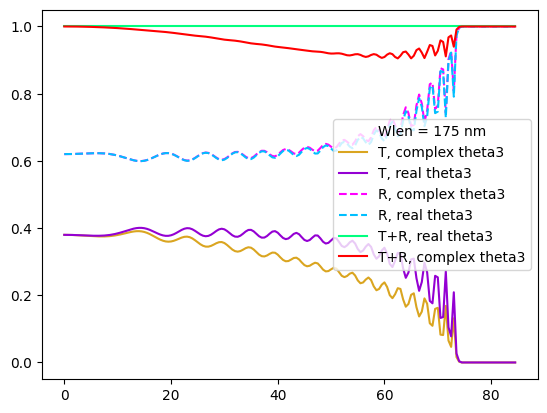

In [4]:
angles = np.arange(0, 85, 0.5)
wlen = 175
photon = PhotonInfo(wlen = wlen, theta_1=angles, mediumStr="lxe")
photonReal = PhotonInfo(wlen = wlen, theta_1=angles, mediumStr="lxe")
photonReal.theta_3 = np.real(photonReal.theta_3)

plt.plot(angles, photon.Wave_TotalTransmission(1000), label = "T, complex theta3")
plt.plot(angles, photonReal.Wave_TotalTransmission(1000), label = "T, real theta3")

plt.plot(angles, photon.Wave_TotalReflection(1000), label = "R, complex theta3", linestyle = "--")
plt.plot(angles, photonReal.Wave_TotalReflection(1000), label = "R, real theta3", linestyle = "--")

plt.plot(angles, photonReal.Wave_TotalTransmission(1000) + photonReal.Wave_TotalReflection(1000), label = "T+R, real theta3")
plt.plot(angles, photon.Wave_TotalTransmission(1000) + photon.Wave_TotalReflection(1000), label = "T+R, complex theta3")

plt.legend(title = f"Wlen = {wlen} nm")
# plt.plot(angles, photon.Wave_TotalReflection(1000))
# plt.plot(angles, photon.Wave_TotalTransmission(1000) + photon.Wave_TotalReflection(1000))

---
## Testing Snell's Law: real vs imaginary indices

-- Material Information: 200 nm --
nSi: (0.9682+2.8615j)
nOxide: (1.5611+0j)
muSi: 0.17979334756494386
muOxide: 0.0
-------------------
Input angle: 35.0 at 200 nm
real only: 67.64114272898185
full n: (5.246198714727796-15.94802349802949j)
-------------------


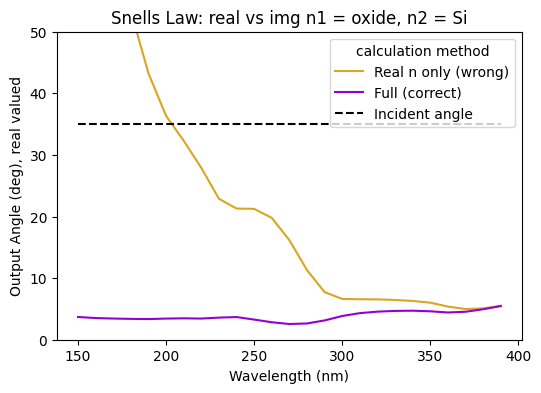

In [5]:
# this proves that we need to take the complex n values for snell's law, 
# but then the real of the output. 
p2 = PhotonInfo(wlen = 200, theta_1=35)
p2.PrintMaterialInfo()

# compare this below with ME.Snells_Law
def Snell_real(n1, n2, theta1):
    arg1 = (n1.real / n2.real) * np.sin(theta1)
    # print(arg1)
    theta2 = np.arcsin(arg1)
    return theta2.real

print("-------------------")
print("Input angle:", p2.theta_1 * rad2deg, f"at {p2.wlen} nm")
print("real only:", Snell_real(p2.nOxide, p2.nSi, p2.theta_1) * rad2deg)
print("full n:", ME.Snells_Law(p2.nOxide, p2.nSi, p2.theta_1)*rad2deg)
print("-------------------")

xwlen = np.arange(150, 400, 10)
theta3_real_list = []
theta3_full_list = []

angle1 = 35
for wlen in xwlen:
    photon = PhotonInfo(wlen = wlen, theta_1=angle1)
    # not the most accurate because Snell's full is done for 1-->2 here but oh well
    
    theta3_real = Snell_real(photon.nOxide, photon.nSi, photon.theta_2)
    theta3_real_list.append(theta3_real)
    
    theta3_full = ME.Snells_Law(photon.nOxide, photon.nSi, photon.theta_2)
    theta3_full_list.append(theta3_full)

## plotting ##
plt.figure(figsize=(6, 4))
plt.plot(xwlen, rad2deg * np.array(theta3_real_list), label="Real n only (wrong)")
plt.plot(xwlen, rad2deg * np.array(theta3_full_list), label="Full (correct)")
plt.hlines(angle1, xwlen[0], xwlen[-1], color = 'black', linestyle = "--", label="Incident angle")

plt.ylim(0, 50)
plt.legend(title = "calculation method", loc = "upper right")

plt.xlabel("Wavelength (nm)")
plt.ylabel("Output Angle (deg), real valued")
plt.title(f"Snells Law: real vs img n1 = oxide, n2 = Si")
plt.show()

---
### PN Junction and Snell's law refraction

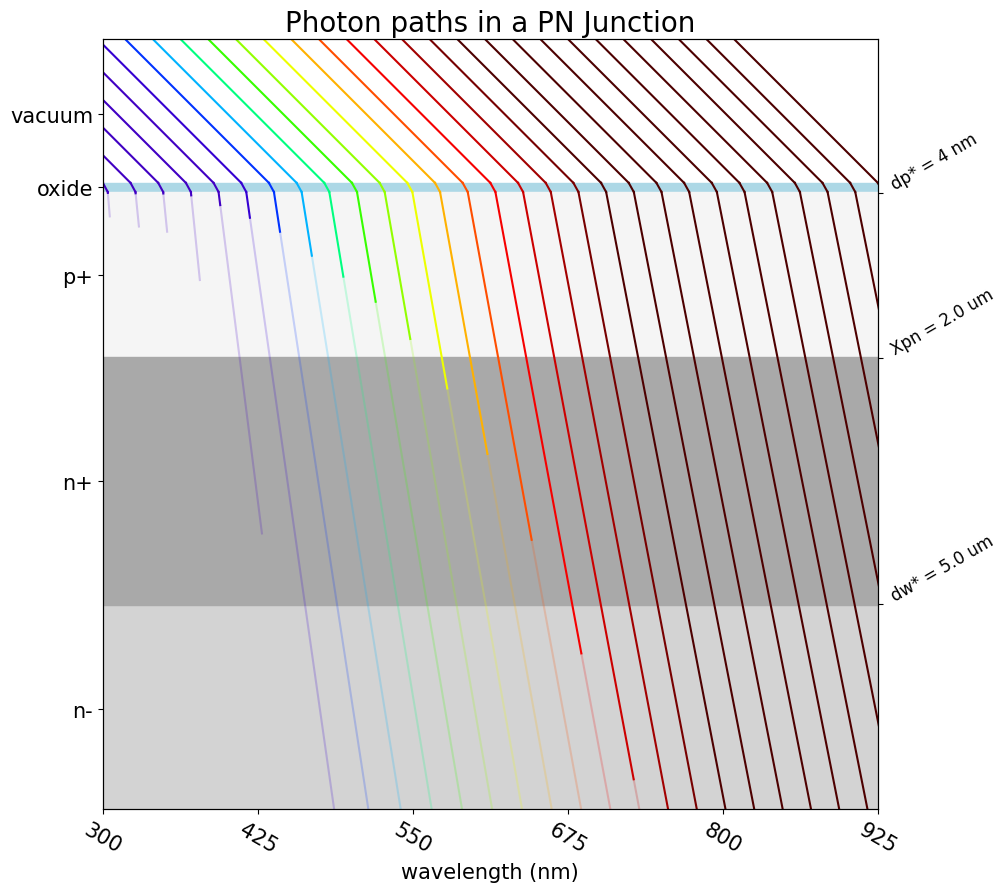

In [6]:
# Create a figure and axis
fig, ax = plt.subplots(figsize = (10, 10))
xlow = 300
xhigh = 1000
xstep = 25
xwlen = np.arange(xlow, xhigh + xstep, xstep)
startAngle = 45

pn = PNJunction(tOxide = 110, dp_star = 4, dp = 5)

scaleNregion = 1.5
si_height = pn.dw_star * scaleNregion
f_si = 0.8
height = si_height/f_si
width = height # this being square sets the 'bias' (or not) of the slope of the lines

# Draw the rectangles
si_rect     = plt.Rectangle(xy = (0, 0),    width = width,  height = si_height,     color='lightgray')
oxide_rect  = plt.Rectangle(xy = (0,        si_height), width = width,  height = pn.tOxide,  color='lightblue')
p_rect      = plt.Rectangle(xy = (0,        si_height - pn.dp_star - pn.tp),     width = width,  height = pn.tp, color='whitesmoke')
n_rect      = plt.Rectangle(xy = (0,        si_height - pn.Xpn - pn.tn),     width = width,  height = pn.tn, color='darkgray')

# Add the rectangles to the axis
ax.add_patch(si_rect)
ax.add_patch(oxide_rect)
ax.add_patch(p_rect)
ax.add_patch(n_rect)

scaleWlentoWidth = lambda xwl, wlenlist, width: (xwl - min(wlenlist)) / ((max(wlenlist) - min(wlenlist))/width)
scaleWidthtoWlen = lambda x, wlenlist, width: x * ((max(wlenlist) - min(wlenlist))/width) + min(wlenlist)

for wlen in xwlen:
    photon = PhotonInfo(wlen = wlen, theta_1=startAngle)    
    # photon.PrintPhotonInfo()
    plot_color = MS.wavelength_to_rgb(wlen)
    
    l = height
    x2 = scaleWlentoWidth(wlen, xwlen, width) 
    y2 = height*f_si + pn.tOxide #wlen value
    
    x1 = x2 - l*np.sin(photon.theta_1) # swap sine and cos because measuring from normal
    y1 = y2 + l*np.cos(photon.theta_1)

    ax.plot([x1, x2], [y1, y2], linewidth = 1.5, color=plot_color)
    
    # # second line (in oxide)
    loxide = pn.tOxide
    x3 = x2 + np.tan(photon.theta_2)*loxide
    y3 = y2 - loxide
    ax.plot([x2, x3], [y2, y3], linewidth = 1.5, color=plot_color)
    
    # third line (in Bulk)
    lSi = 2/photon.muSi
    y4 = y3 - lSi*np.cos(photon.theta_3)
    x4 = x3 + lSi*np.sin(photon.theta_3)    
    ax.plot([x3, x4], [y3, y4], linewidth = 1.5, color=plot_color)
    
    ldead = 50/photon.muSi
    y5 = y4 - ldead*np.cos(photon.theta_3)
    x5 = x4 + ldead*np.sin(photon.theta_3)
    ax.plot([x4, x5], [y4, y5], linewidth = 1.5, color=plot_color, alpha = 0.2)
        

## plotting ##
# Set the xticks to go over xwlen
xticks = scaleWlentoWidth(xwlen[::5], xwlen[::5], width)
ax.set_xticks(xticks)
ax.set_xticklabels(xwlen[::5], rotation=-30, fontsize = 15)
ax.set_xlabel("wavelength (nm)", fontsize = 15)

yticks = [p_rect.get_y() + p_rect.get_height()/2, n_rect.get_y() + n_rect.get_height()/2, oxide_rect.get_y() + oxide_rect.get_height()/2, (si_height- pn.dw_star)/2, height - height*(1-f_si)/2]
ytLabels = ["p+", "n+", "oxide", "n-", "vacuum"]
ax.set_yticks(yticks)
ax.set_yticklabels(ytLabels, fontsize = 15)

ax.set_title("Photon paths in a PN Junction", fontsize = 20)
# Set the aspect ratio and limits of the axis
ax.set_aspect('equal')
viewGap =scaleWlentoWidth(400, xwlen, width)
ax.set_xlim(0, width)
ax.set_ylim(0, width)


# Create a twin y-axis on the right side
yticks_edges = [oxide_rect.get_y(), p_rect.get_y(), n_rect.get_y()] 
yticks_edges_labels = [f"dp* = {pn.dp_star} nm", f"Xpn = {pn.Xpn/1000} um", f"dw* = {pn.dw_star/1000} um"]

ax2 = ax.twinx()
ax2.set_yticks(yticks_edges)
ax2.set_yticklabels(yticks_edges_labels, fontsize=12, rotation = 30, verticalalignment = 'bottom')
ax2.set_ylim(0, width)
ax2.set_xlim(0, width)


# Show the plot
plt.show()

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


[2475.0, 1500.0, 3055.0, 500.0, 3562.5]
1000.0
0.0

(0.0, 3750.0)
1945.0
2000.0


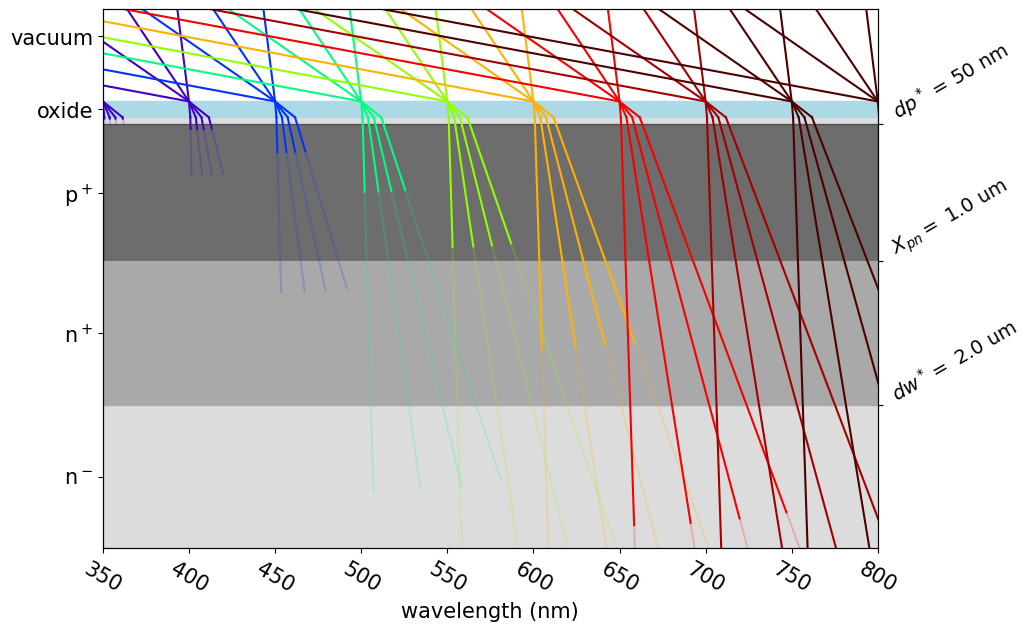

In [7]:
# Create a figure and axis
fig, ax = plt.subplots(figsize = (10, 7))
xlow = 350
xhigh = 800
xstep = 50
xwlen = np.arange(xlow, xhigh + xstep, xstep)
startAngle = 45
xAngles = [75, 45, 25, 5]

pn = PNJunction(tOxide = 110, dp_star = 50, dp = 50, Xpn = 1000, dw_star = 2000)

scaleNregion = 1.5
si_height = pn.dw_star * scaleNregion
f_si = 0.8
height = si_height/f_si
width = height # this being square sets the 'bias' (or not) of the slope of the lines

# Draw the rectangles
si_rect = plt.Rectangle(xy = (0, 0),    width = width,  height = si_height, color='gainsboro')
oxide_rect = plt.Rectangle(xy = (0, si_height), width = width,  height = pn.tOxide,  color='lightblue')
p_rect = plt.Rectangle(xy = (0, si_height - pn.dp_star - pn.tp),     width = width,  height = pn.tp, color='black', alpha = 0.5)
n_rect = plt.Rectangle(xy = (0, si_height - pn.Xpn - pn.tn),     width = width,  height = pn.tn, color='darkgray')

# Add the rectangles to the axis
ax.add_patch(si_rect)
ax.add_patch(oxide_rect)
ax.add_patch(p_rect)
ax.add_patch(n_rect)

scaleWlentoWidth = lambda xwl, wlenlist, width: (xwl - min(wlenlist)) / ((max(wlenlist) - min(wlenlist))/width)
scaleWidthtoWlen = lambda x, wlenlist, width: x * ((max(wlenlist) - min(wlenlist))/width) + min(wlenlist)

for wlen in xwlen:
    for angle in xAngles:
        photon = PhotonInfo(wlen = wlen, theta_1=angle)    
        # photon.PrintPhotonInfo()
        plot_color = MS.wavelength_to_rgb(wlen)
        
        l = height
        x2 = scaleWlentoWidth(wlen, xwlen, width) 
        y2 = height*f_si + pn.tOxide #wlen value
        
        x1 = x2 - l*np.sin(photon.theta_1) # swap sine and cos because measuring from normal
        y1 = y2 + l*np.cos(photon.theta_1)

        ax.plot([x1, x2], [y1, y2], linewidth = 1.5, color=plot_color)
        
        # # second line (in oxide)
        loxide = pn.tOxide
        x3 = x2 + np.tan(photon.theta_2)*loxide
        y3 = y2 - loxide
        ax.plot([x2, x3], [y2, y3], linewidth = 1.5, color=plot_color)
        
        # third line (in Bulk)
        lSi = 1/photon.muSi
        y4 = y3 - lSi*np.cos(photon.theta_3)
        x4 = x3 + lSi*np.sin(photon.theta_3)    
        ax.plot([x3, x4], [y3, y4], linewidth = 1.5, color=plot_color)
        
        ldead = 4/photon.muSi
        y5 = y4 - ldead*np.cos(photon.theta_3)
        x5 = x4 + ldead*np.sin(photon.theta_3)
        ax.plot([x4, x5], [y4, y5], linewidth = 1.5, color=plot_color, alpha = 0.2)
        

## plotting ##
# ax.set_title("PN Junction model and Photon Paths", fontsize = 20, pad = 20)
# plt.subplots_adjust(top=0.9)  # Adjust the top margin (default is 0.95)
# Set the aspect ratio and limits of the axis
# ax.set_aspect('equal')
# viewGap =scaleWlentoWidth(400, xwlen, width)
ax.set_xlim(0, width)
ax.set_ylim(0, height)

# Set the xticks to go over xwlen
xticks = scaleWlentoWidth(xwlen, xwlen, width)
ax.set_xticks(xticks)
ax.set_xticklabels(xwlen, rotation=-30, fontsize = 15)
ax.set_xlabel("wavelength (nm)", fontsize = 15)

yticks = [p_rect.get_y() + p_rect.get_height()/2, n_rect.get_y() + n_rect.get_height()/2, oxide_rect.get_y() + oxide_rect.get_height()/2, n_rect.get_y()/2, height - (height - oxide_rect.get_y())/4]
print(yticks)
print(n_rect.get_y())
print(ax.get_ylim()[0])
print()
ytLabels = [r"p$^+$", r"n$^+$", "oxide", "n$^-$", "vacuum"]
ax.set_yticks(yticks)
ax.set_yticklabels(ytLabels, fontsize = 15)


# Create a twin y-axis on the right side
yticks_edges = [n_rect.get_y(), p_rect.get_y(), p_rect.get_y() + p_rect.get_height()]
yticks_edges_labels = [fr"$dw^* =$ {pn.dw_star/1000} um", r"$X_{pn} =$" + f" {pn.Xpn/1000} um", fr"$dp^*$ = {pn.dp_star} nm"]

ax2 = ax.twinx()
print(ax.get_ylim())
ax2.set_ylim(ax.get_ylim())

print(p_rect.get_y() - oxide_rect.get_height()/2)
print(si_height - pn.dp_star - pn.tp)

ax2.set_yticks(yticks_edges)
ax2.set_yticklabels(yticks_edges_labels, fontsize=14, rotation = 30, verticalalignment = 'bottom')


# Show the plot
plt.show()

In [8]:
# Define the range of X and Y
X = np.arange(120, 901, 2.5)
Y = np.arange(0, 91, 5)

# Calculate Z
Z = np.zeros((len(Y), len(X)))
for i, angle in enumerate(Y):
    for j, wavelength in enumerate(X):
        # Calculate Z value based on your calculation
        Z[i, j] = PhotonInfo(wavelength, angle).theta_3 * rad2deg

# Create a meshgrid for X and Y
X, Y = np.meshgrid(X, Y)


/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_12064/2235759912.py:10: ComplexWarning: Casting complex values to real discards the imaginary part
  Z[i, j] = PhotonInfo(wavelength, angle).theta_3 * rad2deg


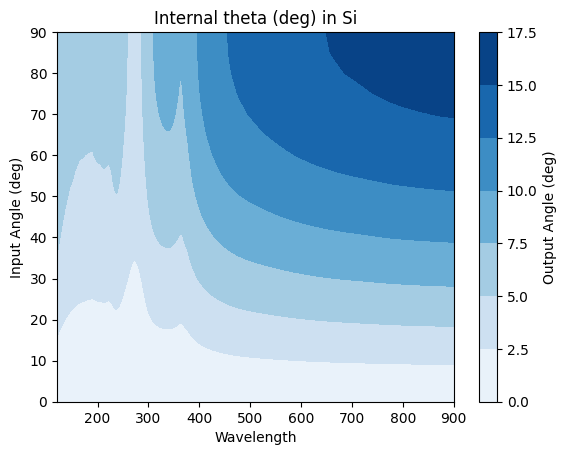

In [9]:
# Create the contour plot
plt.contourf(X, Y, Z, cmap='Blues')

# Set labels and title
plt.xlabel('Wavelength')
plt.ylabel('Input Angle (deg)')
plt.title('Internal theta (deg) in Si')

# Show the plot
plt.colorbar(label='Output Angle (deg)')
plt.show()


---
## Testing Absorption Equations

These are the absorption functions defined by Nicolas. This is the exponential attenuation in the medium, and these equations are essentially 'how much is living at the top of the region multiplied by how much is absorbed in the region'. $t_x$ are the thickness' of the region, and $\theta_3$ is the angle inside the bulk. $W_{p, n}$ are the probability or **W**eights that the photon is absorbed in that region. 

$$ W_p = e^{-\mu (t_d) / \cos\theta_3}(1-e^{-\mu t_p/\cos\theta_3})] $$

$$ W_p = e^{-\mu (t_d+t_p) / \cos\theta_3}(1-e^{-\mu t_n/\cos\theta_3})] $$

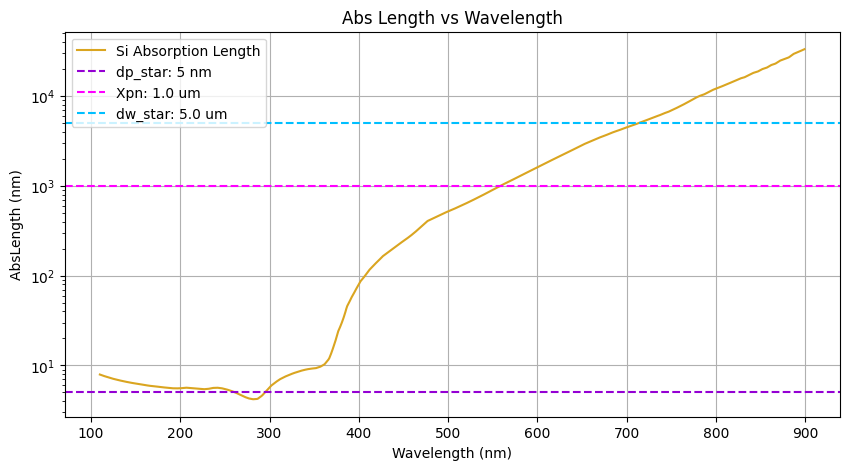

In [10]:
xwlen = np.arange(110, 900, 1)
photon = PhotonInfo(wlen = xwlen, theta_1 = 0)
dh = OpticsData()
pn = PNJunction(dp_star = 5, Xpn = 1e3)

plt.figure(figsize = (10, 5))
plt.semilogy(xwlen, 1/photon.muSi, label = "Si Absorption Length")

nextCol = lambda: plt.gca()._get_lines.get_next_color()

plt.axhline(y=pn.dp_star, linestyle='--', color = nextCol(), label=f'dp_star: {pn.dp_star} nm')
plt.axhline(y=pn.Xpn, linestyle='--', color = nextCol(), label=f'Xpn: {pn.Xpn/1000} um')
plt.axhline(y=pn.dw_star, linestyle='--', color = nextCol(), label=f'dw_star: {pn.dw_star/1000} um')

plt.ylabel("AbsLength (nm)")
plt.xlabel("Wavelength (nm)")
plt.title("Abs Length vs Wavelength")

# plt.xlim(300, 900)

# plt.ylim(1, 20)

plt.grid()
plt.legend()
plt.show()

-- Material Information: 800 nm --
nSi: (3.669244+0.0052640000000000004j)
nOxide: (1.4528+0j)
muSi: 8.268671864248336e-05
muOxide: 0.0
-- Photon Information: 800 nm --
Theta1: 85.0 degrees
Theta2: (43.29121070651867+0j) degrees
Theta3: (15.753428611915215-0.023187580701043806j) degrees
Pure R, T 1<->2: 0.60686176554927630.393138234450724
Pure R, T 2<->3: 0.194229025706029, 0.8057708265310648

-- Material Information: 1200 nm --
nSi: (3.52202+0j)
nOxide: (1.4480333333333333+0j)
muSi: 0.0
muOxide: 0.0


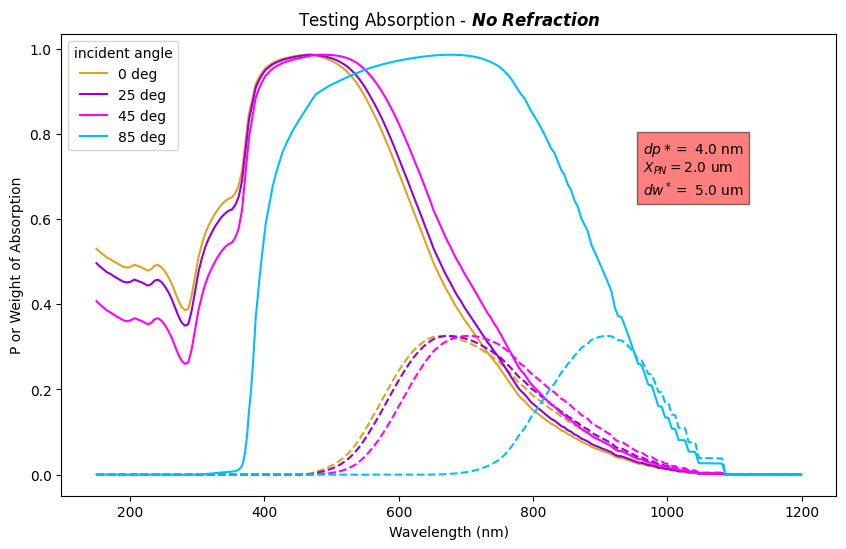

In [11]:
xwlen = np.arange(150, 1200, 1)
thetaList = [0, 25, 45, 85]

pn = PNJunction(tOxide = 110, dp_star = 4, dp = 5)

photon = PhotonInfo(wlen = 800, theta_1=85)
photon.PrintMaterialInfo()
photon.PrintPhotonInfo()
photon = PhotonInfo(wlen = 1200, theta_1=85)
photon.PrintMaterialInfo()

plt.figure(figsize = (10, 6))
for i, theta in enumerate(thetaList):
    col = ms.allColsStr[i]
    Wp, Wn = [], []
    for wl in xwlen:
        photon = PhotonInfo(wlen = wl, theta_1=theta)
        photon.theta_3 = theta/rad2deg
        WnVal = pn.calcWp(photon)
        WpVal = pn.calcWn(photon)
        
        Wp.append(WnVal)
        Wn.append(WpVal)
    
    plt.plot(xwlen, Wp, label=f"{theta:0.0f} deg", color = col)
    plt.plot(xwlen, Wn, color = col, linestyle = "--")

plt.text(0.75, 0.65, '\n'.join(pn.printPNInfo()), fontsize = 10, bbox=dict(facecolor='red', alpha=0.5), transform=plt.gca().transAxes)

plt.ylabel("P or Weight of Absorption")
plt.xlabel("Wavelength (nm)")

# plt.rcParams['text.usetex'] = False
plt.title(r"Testing Absorption - $ \boldsymbol{No~Refraction} $")

plt.legend(title=f"incident angle")
plt.show()

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


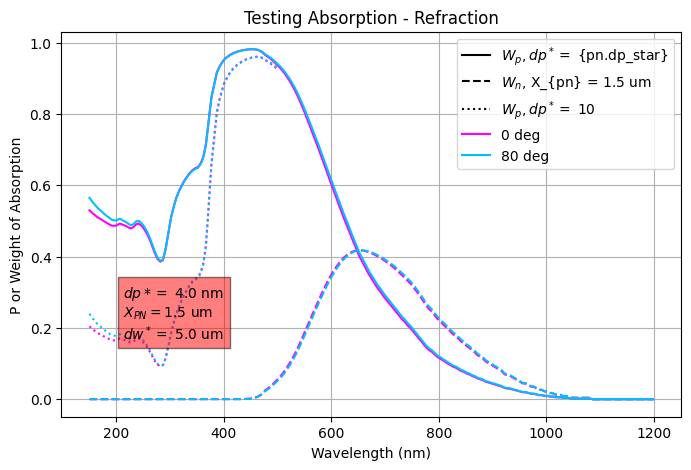

Wp at 400 nm: (0.9505303226162999+0.00010916904393113808j)
Wn at 400 nm: (5.455568191957602e-09+2.3511176715941727e-10j)


In [12]:
xwlen = np.arange(150, 1200, 1)
thetaList = [0, 80]

plt.figure(figsize=(8, 5))
pn = PNJunction(tOxide = 16.5, dp_star = 4, Xpn = 1.5e3, dw_star=5e3)
pn3 = copy.deepcopy(pn)
pn3.dp_star = 10
pn2 = PNJunction(tOxide = 110, dp_star = 4, Xpn = 4e3, dw_star=8e3)

plt.plot([], [], linestyle = "-", label = r"$W_p, dp^* = $ {pn.dp_star}", color = "black")
plt.plot([], [], linestyle = "--", label = r"$W_n$, X_{pn} = " + f"{pn.Xpn/1000} um", color = "black")
plt.plot([], [], linestyle = ":", label = fr"$W_p, dp^* = $ {pn3.dp_star}", color = "black", linewidth = 1.5)

ms.ResetColorCycle()
for i, theta in enumerate(thetaList):
    if i == 0:
        col = ms.lxe2.col
    if i == 1:
        col = ms.cf4.col
    
    Wp = np.array([pn.calcWp(PhotonInfo(wlen = wl, theta_1=theta)) for wl in xwlen])
    wp2 = np.array([pn2.calcWp(PhotonInfo(wlen = wl, theta_1=theta)) for wl in xwlen])
    wp3 = np.array([pn3.calcWp(PhotonInfo(wlen = wl, theta_1=theta)) for wl in xwlen])
    
    Wn = np.array([pn.calcWn(PhotonInfo(wlen = wl, theta_1=theta)) for wl in xwlen])
        
    plt.plot(xwlen, Wp, label=f"{theta:0.0f} deg", color = col)
    # plt.plot(xwlen, wp2, color = col, linewidth = 3)
    plt.plot(xwlen, Wn, color = col, linestyle = "--")
    plt.plot(xwlen[xwlen < 500], wp3[xwlen < 500], color = col, linestyle = ":", linewidth = 1.5)

plt.text(0.1, 0.2, '\n'.join(pn.printPNInfo()), fontsize = 10, bbox=dict(facecolor='red', alpha=0.5), transform=plt.gca().transAxes)

plt.ylabel("P or Weight of Absorption")
plt.xlabel("Wavelength (nm)")
plt.title("Testing Absorption - Refraction")

# plt.xlim(350, 500)
# plt.ylim(0, 0.2)

plt.legend(title=f"", loc = "upper right")
plt.grid()
plt.show()


testWlen = 400
Wtest = pn.calcWp(PhotonInfo(wlen = testWlen, theta_1=theta))
WnTest = pn.calcWn(PhotonInfo(wlen = testWlen, theta_1=theta))
print(f"Wp at {testWlen} nm: {Wtest}")
print(f"Wn at {testWlen} nm: {WnTest}")

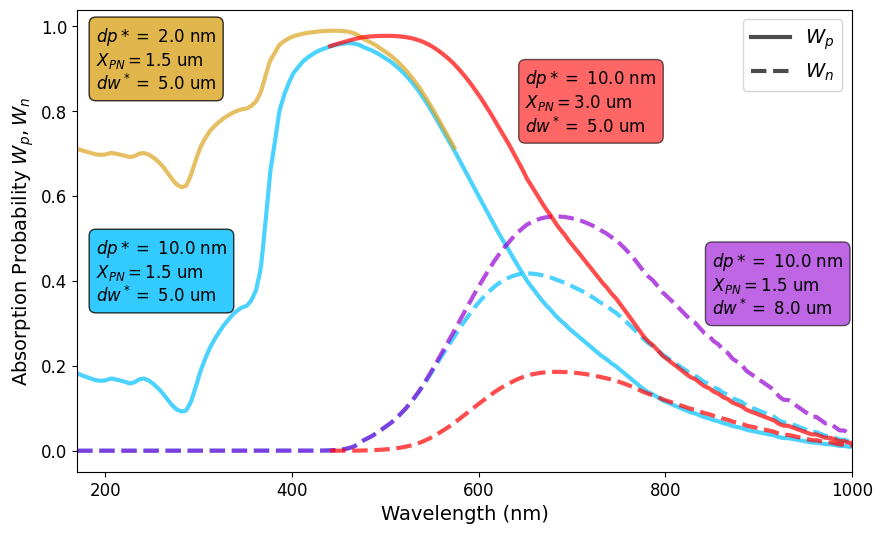

In [13]:
from matplotlib.ticker import MultipleLocator
xwlen = np.arange(170, 1200, 1)
thetaList = [0, 80]

plt.figure(figsize=(10, 6))
pn = PNJunction(tOxide = 16.5, dp_star = 10, Xpn = 1.5e3, dw_star=5e3)

fsize = 12

## shallower dp_star
pn2 = copy.deepcopy(pn)
pn2.dp_star = 2

## deeper dw_star
pn3 = copy.deepcopy(pn)
pn3.dw_star = 8e3

pn4 = copy.deepcopy(pn)
pn4.Xpn = 3e3

ms.ResetColorCycle()

lStyle = {"linewidth": 3, "alpha": 0.7}

plt.plot([], [], linestyle = "-", label = r"$W_p$", color = "black", **lStyle)
plt.plot([], [], linestyle = "--", label = r"$W_n$", color = "black", **lStyle)


## dp 1
Wp = pn.calcWp(PhotonInfo(wlen = xwlen, theta_1=thetaList[0]))    
plt.plot(xwlen, Wp, color = ms.cf4.col, linestyle = "-", **lStyle)

Wpangle = pn.calcWp(PhotonInfo(wlen = xwlen, theta_1=80))
Wnangle = pn.calcWn(PhotonInfo(wlen = xwlen, theta_1=80))
# plt.plot(xwlen, Wpangle, color = ms.cf4.col, linestyle = ":", **lStyle)
# plt.plot(xwlen, Wnangle, color = ms.cf4.col, linestyle = ":", **lStyle)

Wn = pn.calcWn(PhotonInfo(wlen = xwlen, theta_1=thetaList[0]))
plt.plot(xwlen, Wn, color = ms.cf4.col, linestyle = "--", **lStyle)
plt.text(190, 0.35, '\n'.join(pn.printPNInfo()), fontsize = fsize, bbox=dict(facecolor=ms.cf4.col, alpha=0.8, boxstyle="round,pad=0.4"))

## dp2
Wp2 = pn2.calcWp(PhotonInfo(wlen = xwlen, theta_1=thetaList[0]))
plt.plot(xwlen[xwlen < 575], Wp2[xwlen < 575], color = ms.air.col, linestyle = "-", **lStyle)
plt.text(190, 0.85, '\n'.join(pn2.printPNInfo()), fontsize = fsize, bbox=dict(facecolor=ms.air.col, alpha=0.8, boxstyle="round,pad=0.4"))

## pn3
wn3 = pn3.calcWn(PhotonInfo(wlen = xwlen, theta_1=thetaList[0]))
plt.plot(xwlen, wn3, color = ms.lxe.col, linestyle = "--", **lStyle)
plt.text(850, 0.32, '\n'.join(pn3.printPNInfo()), fontsize = fsize, bbox=dict(facecolor=ms.lxe.col, alpha=0.6, boxstyle="round,pad=0.4"))

## pn4
wp4 = pn4.calcWp(PhotonInfo(wlen = xwlen, theta_1=thetaList[0]))
wn4 = pn4.calcWn(PhotonInfo(wlen = xwlen, theta_1=thetaList[0]))

plt.plot(xwlen[xwlen>440], wp4[xwlen>440], color = ms.red.col, linestyle = "-", **lStyle)
plt.plot(xwlen[xwlen>440], wn4[xwlen>440], color = ms.red.col, linestyle = "--", **lStyle)
plt.text(650, 0.75, '\n'.join(pn4.printPNInfo()), fontsize = fsize, bbox=dict(facecolor=ms.red.col, alpha=0.6, boxstyle="round,pad=0.4"))

plt.ylabel(r"Absorption Probability $W_p, W_n$", fontsize = 14)
plt.xlabel("Wavelength (nm)", fontsize = 14)
# plt.title("Testing Absorption - Refraction")

plt.tick_params(axis='both', which='major', labelsize=12)
plt.gca().xaxis.set_major_locator(MultipleLocator(200))  # X ticks every 100nm

plt.xlim(170, 1000)
# plt.ylim(0, 0.2)

plt.legend(title=None, loc = "upper right", fontsize = 14)
# plt.grid()
plt.show()


# testWlen = 400
# Wtest = pn.calcWp(PhotonInfo(wlen = testWlen, theta_1=theta))
# WnTest = pn.calcWn(PhotonInfo(wlen = testWlen, theta_1=theta))
# print(f"Wp at {testWlen} nm: {Wtest}")
# print(f"Wn at {testWlen} nm: {WnTest}")

---
## Fresnels Equations for two boundaries: Pure, Ray and Wave Solutions
The photons are going from medium 1-->2-->3, being vacuum or the medium, oxide, and silicon bulk
$T_{12}$ refers to the Fresnel transmission from medium 1-->2, while $t_{12}$ and $r_{12}$ are the field coefficients. 

* __Pure__: Transmission is simply $$ T_{13} = T_{12} \times T_{23} $$
* __Ray__: Geometric reflections (like wave optics) $$ T_{13} = T_{12} T_{23} A \frac{1}{1 - R_{23}R_{21}A^2} $$
$$A = e^{-\mu t_{oxide}/\cos\theta_2}$$
where A is the absorbtion inside the oxide of thickness $t_{oxide}$ and $\theta_2$ is the angle of refraction inside the oxide
* __Wave__: Use the wave optics solution (Kurtis thesis) for the thin surface solution. This equations is different for S and P polarized light and should be averaged for our unpolarized light. 
$$ T_{13, \parallel or \perp} = \frac{n_3 \cos\theta_3}{n_1 \cos\theta_1} \Big( \frac{t_{12}t_{23}}{1 - r_{23}r_{12}e^{-i\delta}} \Big)^2  _{\parallel or \perp} $$
$$ \delta = \frac{4\pi n_2 t_{oxide}\cos\theta_2}{\lambda} $$

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/si_vuye_300k.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/temp_extrapolation/vuye_silicon_extended160K_1dinterp.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxid

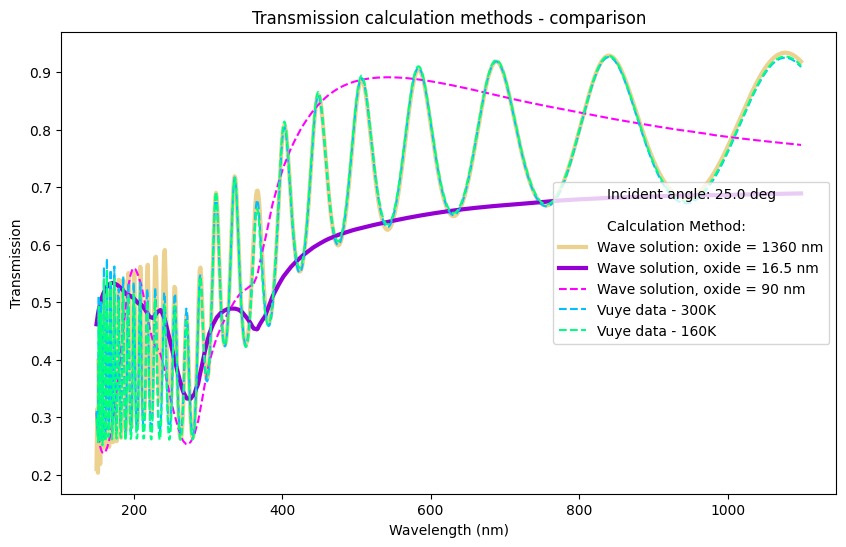

In [14]:
xwlen = np.arange(150, 1100, 1)

t_oxide = 1360
t_oxideThicker = 90
t_oxideSmall = 16.5
angle = 25

yTransPure = np.array([PhotonInfo(wlen = wl, theta_1=angle).Pure_T13(t_oxide)    for wl in xwlen])
yTransRay = np.array([PhotonInfo(wlen = wl, theta_1=angle).Ray_T13(t_oxide)      for wl in xwlen])
yTransFull = np.array([PhotonInfo(wlen = wl, theta_1=angle).Wave_TotalTransmission(t_oxide) for wl in xwlen])
yTransFull_small = np.array([PhotonInfo(wlen = wl, theta_1=angle).Wave_TotalTransmission(t_oxideSmall) for wl in xwlen])
yTransFullThicker = np.array([PhotonInfo(wlen = wl, theta_1=angle).Wave_TotalTransmission(t_oxideThicker) for wl in xwlen])
yTransFBK = np.array([PhotonInfo(wlen = wl, theta_1=angle).Wave_TotalTransmission(1350) for wl in xwlen])

## repeat for much higher k in oxide to test for absorption
yTransFull_highK = []
for wl in xwlen:
    photon = PhotonInfo(wlen = wl, theta_1=angle)
    photon.nOxide = photon.nOxide + 1j
    tt_highK = ME.Wave_TwoLayerTransmission_total(wl, t_oxide, photon.nVacuum, photon.nOxide, photon.nSi, photon.theta_1, photon.theta_2, photon.theta_3)
    yTransFull_highK.append(tt_highK)

plt.figure(figsize=(10, 6))
# plt.plot(xwlen, yTransPure-0.005, label=r"Pure (shifted): $T_{12}T_{13} $")
# plt.plot(xwlen, yTransRay, label="Ray optics: geometric R, T")

plt.plot(xwlen, yTransFull, linewidth = 3, alpha = 0.5, label=f"Wave solution: oxide = {t_oxide} nm")
plt.plot(xwlen, yTransFull_small, linestyle = "-", linewidth = 3, label=f"Wave solution, oxide = {t_oxideSmall} nm")
plt.plot(xwlen, yTransFullThicker, linestyle = "--", label=f"Wave solution, oxide = {t_oxideThicker} nm")

# plt.plot(xwlen, np.array(yTransFull_highK).real, linestyle = "--", label="Wave solution, high k_oxide")
# plt.plot(xwlen, yTransFBK, linestyle = "--", label="oxide = 1350 nm")

## testing vuye data in vis
dh_vuyeRT = OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "si_vuye_300k.txt"))
phVuyeRT = PhotonInfo(wlen = xwlen, theta_1=angle, dataHelper=dh_vuyeRT)
yTransVuyeRT = phVuyeRT.Wave_TotalTransmission(t_oxide)

dh_vuye = OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "temp_extrapolation", "vuye_silicon_extended160K_1dinterp.txt"))
phVuye = PhotonInfo(wlen = xwlen, theta_1=angle, dataHelper=dh_vuye)
yTransVuye = phVuye.Wave_TotalTransmission(t_oxide)

plt.plot(xwlen, yTransVuyeRT, linestyle = "--", label="Vuye data - 300K")
plt.plot(xwlen, yTransVuye, linestyle = "--", label="Vuye data - 160K")

plt.legend(title = f"Incident angle: {angle:0.1f} deg\n\nCalculation Method:", loc = "center right")
ax = plt.gca()
# ax.legend_.get_texts()[2].set_weight('bold')

# plt.xlim(160, 200)

plt.xlabel("Wavelength (nm)")
plt.ylabel("Transmission")
plt.title("Transmission calculation methods - comparison")
plt.show()

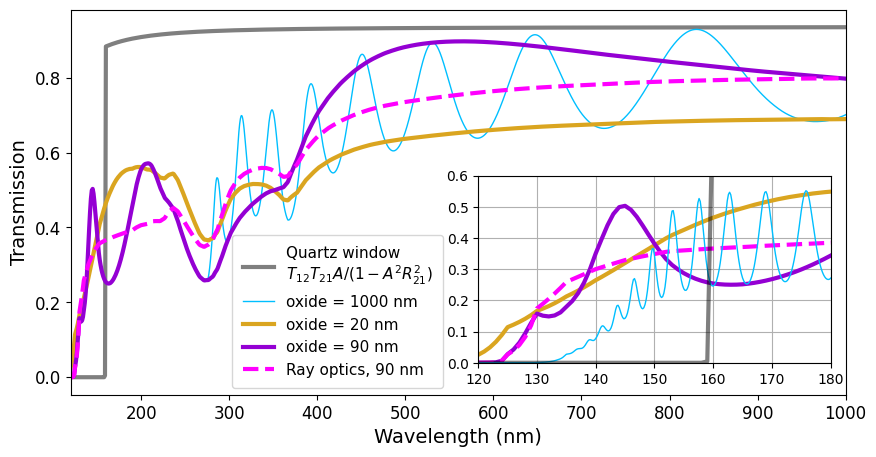

In [15]:
xwlen = np.arange(120, 1000, 1)
xwlen2 = np.arange(120, 1000, 0.1)
xwlen_close = np.arange(120, 250, 0.2)

t_oxide = 1000
t_oxideThicker = 90
t_oxideSmall = 20
angle = 0

yTransPure = np.array([PhotonInfo(wlen = wl, theta_1=angle).Pure_T13(t_oxideThicker)    for wl in xwlen])
yTransRay = np.array([PhotonInfo(wlen = wl, theta_1=angle).Ray_T13(t_oxideThicker)      for wl in xwlen])

yTransFull = PhotonInfo(wlen = xwlen2, theta_1=angle).Wave_TotalTransmission(t_oxide)
yTrans_fbk_zoom = PhotonInfo(wlen = xwlen_close, theta_1=angle).Wave_TotalTransmission(t_oxide)

yTransFull_small = PhotonInfo(wlen = xwlen, theta_1=angle).Wave_TotalTransmission(t_oxideSmall)
yTransFullThicker = PhotonInfo(wlen = xwlen, theta_1=angle).Wave_TotalTransmission(t_oxideThicker)

## repeat for much higher k in oxide to test for absorption
# yTransFull_highK = []
# for wl in xwlen:
#     photon = PhotonInfo(wlen = wl, theta_1=angle)
#     photon.nOxide = photon.nOxide + 0.1j
#     tt_highK = ME.Wave_TwoLayerTransmission_total(wl, t_oxide, photon.nVacuum, photon.nOxide, photon.nSi, photon.theta_1, photon.theta_2, photon.theta_3)
#     yTransFull_highK.append(tt_highK)

## quartz window
qphoton = PhotonInfo(wlen = xwlen, theta_1=0)
Tq, Rq = qphoton.T_R_quartzWindow()

#### plotting ####
fig, ax = plt.subplots(figsize=(10, 5))
thickDict = {"linewidth": 3}

## quartz window
ax.plot(xwlen, Tq, label="Quartz window\n"+r"$T_{12}T_{21}A/(1-A^2R_{21}^2)$", linestyle = "-", color = "k", linewidth = 3, alpha = 0.5)

## oscillating
ax.plot(xwlen2[xwlen2 > 275], yTransFull[xwlen2 > 275], linewidth = 1, alpha = 1, label=f"oxide = {t_oxide} nm", color = ms.cf4.col)

# 20nm
ax.plot(xwlen, yTransFull_small, linestyle = "-", linewidth = 3, color = ms.air.col, label=f"oxide = {t_oxideSmall} nm")

#90 nm
ax.plot(xwlen, yTransFullThicker, linestyle = "-", linewidth=3, label=f"oxide = {t_oxideThicker} nm", color = ms.lxe.col)

## testing ray
ax.plot(xwlen, yTransRay, label=f"Ray optics, {t_oxideThicker} nm", linestyle = "--", color = ms.lxe2.col, linewidth = 3)

## designing
# ax.legend(title = f"Incident angle: {angle:0.1f} deg", loc = "upper left", fontsize = 10, title_fontsize = 10)
ax.legend(title = None, loc = 'lower left',
          bbox_to_anchor=(295, -0.05), bbox_transform=ax.transData,
          fontsize = 11, title_fontsize = 11, fancybox = True, borderpad = 0.7)

## inset
spot = (575, 0.02, 400, 0.5)
axins = inset_axes(ax, width="100%", height="100%", loc="lower left", bbox_to_anchor=spot, bbox_transform=ax.transData)
for line in ax.get_lines()[1:]:
    axins.plot(line.get_xdata(), line.get_ydata(), label=line.get_label(),
               linestyle=line.get_linestyle(), linewidth=line.get_linewidth(),
               color=line.get_color(), alpha=line.get_alpha())
axins.plot(xwlen_close, yTrans_fbk_zoom, linewidth = 1, alpha = 1, label=f"oxide = {t_oxide} nm", color = ms.cf4.col)
axins.plot(xwlen, Tq, label="Quartz window", linestyle = "-", color = "k", linewidth = 3, alpha = 0.5)

axins.set_xlim(120, 180)
axins.set_ylim(0, 0.6)
axins.grid()

# ax.axins.xaxis.set_major_locator(MultipleLocator(200))  # X ticks every 100nm
ax.tick_params(axis='both', which='major', labelsize=12)

ax.set_xlim(120, 1000)
# ax.grid()
ax.set_xlabel("Wavelength (nm)", fontsize = 14)
ax.set_ylabel("Transmission", fontsize = 14)
ax.tick_params(axis='both', which='major', labelsize=12)
plt.show()

# print(qphoton.muOxide[xwlen < 300])


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/numpy/ma/core.py:3371: ComplexWarning: Casting complex values to real discards the imaginary part
  _data[indx] = dval


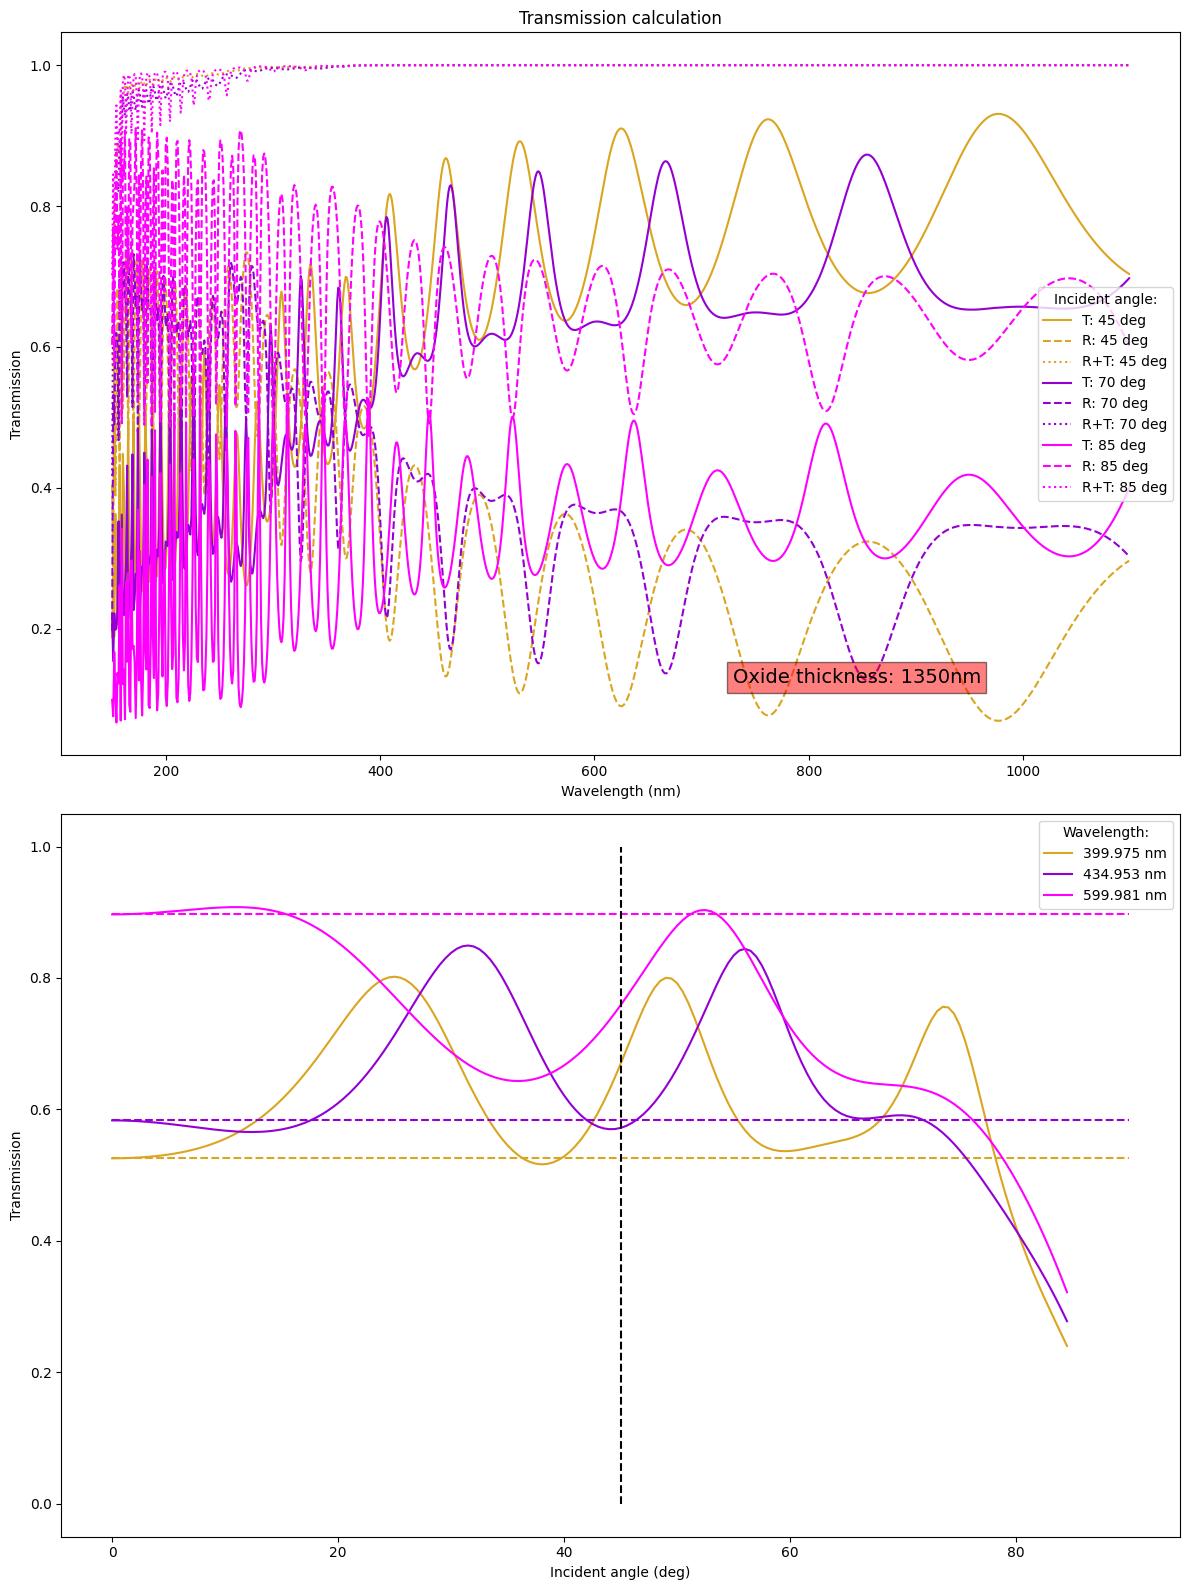

In [16]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize = (12, 16))

thetaList = [0, 25, 45, 70, 85]
xAngle = np.arange(0, 85, 0.5)
wlenList = [128, 155, 176, 250, 400, 660, 800]
wlenList = [399.975, 434.953, 599.981]
xwlen = np.arange(150, 1100, 1)

pn = PNJunction(tOxide = 1350, dp_star = 4, dp = 5)

# vs wavelength
for i, angle in enumerate(thetaList[2:]):
    col = ms.allColsStr[i]
    yTransFull = np.array([ PhotonInfo(wlen = wl, theta_1=angle).Wave_TotalTransmission(pn)     for wl in xwlen ])
    ax1.plot(xwlen, yTransFull, linestyle = "-", label = f"T: {angle} deg", color = col)
    
    yRefFull = np.array([ PhotonInfo(wlen = wl, theta_1=angle).Wave_TotalReflection(pn)         for wl in xwlen ])
    ax1.plot(xwlen, yRefFull, linestyle = "--", label = f"R: {angle} deg", color = col)
    
    ax1.plot(xwlen, yTransFull + yRefFull, linestyle = ":", label = f"R+T: {angle} deg", color = col)
ax1.set_xlabel("Wavelength (nm)")
ax1.set_ylabel("Transmission")
ax1.legend(title = f"Incident angle:")

ax1.text(0.6, 0.1, f"Oxide thickness: {pn.tOxide:0.0f}nm", fontsize = 14, bbox=dict(facecolor='red', alpha=0.5), transform=ax1.transAxes)

## vs angle
for i, wlen in enumerate(wlenList):
    yTransFull = np.array([ PhotonInfo(wlen = wlen, theta_1=angle).Wave_TotalTransmission(pn)   for angle in xAngle ])
    lstyle = "-" if i < len(ms.allColsStr) else "--"
    ax2.plot(xAngle, yTransFull, linestyle = lstyle, label = f"{wlen} nm")
    ax2.hlines(yTransFull[0], 0, 90, color = ms.allColsStr[i], linestyle = "--")
ax2.set_xlabel("Incident angle (deg)")
ax2.set_ylabel("Transmission")
ax2.legend(title = f"Wavelength:")

ax2.vlines(45, 0, 1, color = 'black', linestyle = "--", label = "Normal incidence")

ax1.set_title("Transmission calculation")
plt.tight_layout()
plt.show()


[]

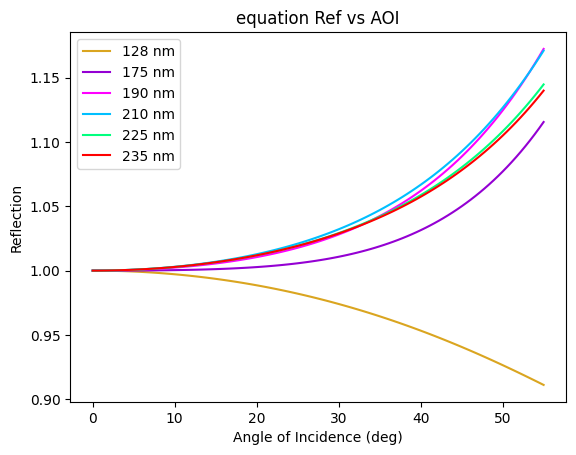

In [17]:
tOx_showRef = 17
xAngles = np.linspace(0, 55, 100)
vlines = [128, 175, 190, 210, 225, 235]
    
for i, wlen in enumerate(vlines):
    col = ms.allColsStr[i]
    photon = PhotonInfo(wlen = wlen, theta_1=xAngles)
    Ref = photon.Wave_TotalReflection(thick_oxide=tOx_showRef)
    Ref0 = Ref/Ref[0]
    plt.plot(xAngles, Ref0, color = col, label = f"{wlen} nm")

plt.title("equation Ref vs AOI")
plt.xlabel("Angle of Incidence (deg)")
plt.ylabel("Reflection")
plt.legend()
plt.plot()


[]

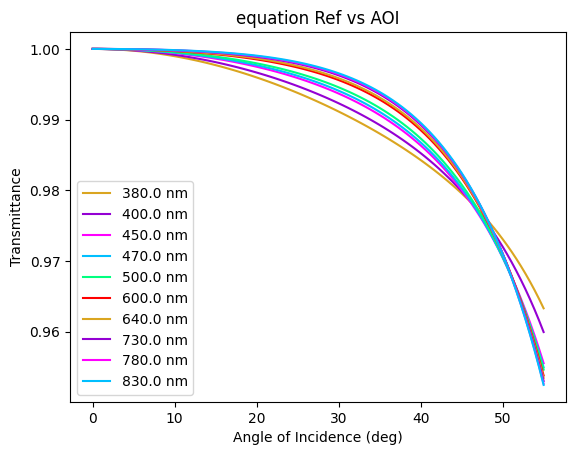

In [18]:
vlines=[380.0, 400.0, 450.0, 470.0, 500.0, 600.0, 640.0, 730.0, 780.0, 830.0]

tOx_showRef = 18
xAngles = np.linspace(0, 55, 100)

    
for i, wlen in enumerate(vlines):
    col = ms.GetNextColor()
    photon = PhotonInfo(wlen = wlen, theta_1=xAngles)
    Ref = photon.T_total_windowAndOxide(thick_oxide=tOx_showRef)
    Ref0 = Ref/Ref[0]
    plt.plot(xAngles, Ref0, color = col, label = f"{wlen} nm")

plt.title("equation Ref vs AOI")
plt.xlabel("Angle of Incidence (deg)")
plt.ylabel("Transmittance")
plt.legend()
plt.plot()


### Quartz window optics
This is purely ray optics, with three different geometric series of $R,T$ to handle the infinite 'bouncebacks' between interfaces. The photon is going from $n_1 \rightarrow n_2(quartz) \rightarrow n_1$ (back to vacuum) before it encounters the silicon.

The reflectivity of the quartz is given by the reflection of the first interface, $R_{12}$, and the light that is transmitted, reflected off the inside of the window (geometrically), $R_{21}$ and then transmitted back through the top, $T_{21}$
$$ R_{quartz} = layer1 + inTop\cdot Ref\cdot outTop + inTop\cdot Ref ^3\cdot outTop + ... $$
$$ R_{quartz} = R_{12} + T_{12}(R_{12})T_{21} + T_{12}(R_{12} R_{12} R_{12})T_{21} + ...$$
$$ R_q = R_{12} + T_{12}R_{12}T_{21} \big( 1+  R_{12}^2 + R_{12}^4 + ... \big)$$
$$ R_q = R_{12} + \frac{T_{12}T_{21}R_{12}}{1 - R_{12}^2} $$

Similarly, but a bit simpler for the window Transmission of the quartz $T_q$:
$$ T_quartz = throughTop \cdot throughBottom + tTop \cdot bounceAround^1 \cdot tBottom + tTop \cdot bounceAround^2 \cdot tBottom + ... $$
$$ T_{quartz} = T_{12} T_{21} + T_{12} (R_{21}R_{21}) T_{21} + T_{12} (R_{21}R_{21})^2 T_{21} + ... $$
$$ T_q = \frac{T_{12} T_{21}}{1 - R_{21}^2 }$$

Taking the reflectivity and transmission of the sipm (including the oxide layer) as $R_{Si}$ and $T_{Si}$, we can combine the systems now:

$$ T_{total} = T_q T_{Si} + T_q (R_{Si} R_q) T_{Si} + T_q (R_{Si} R_q)^2 T_{Si} + ... $$
$$ T_{total} = \frac{T_q T_{Si}}{1 - R_{Si} R_q} $$

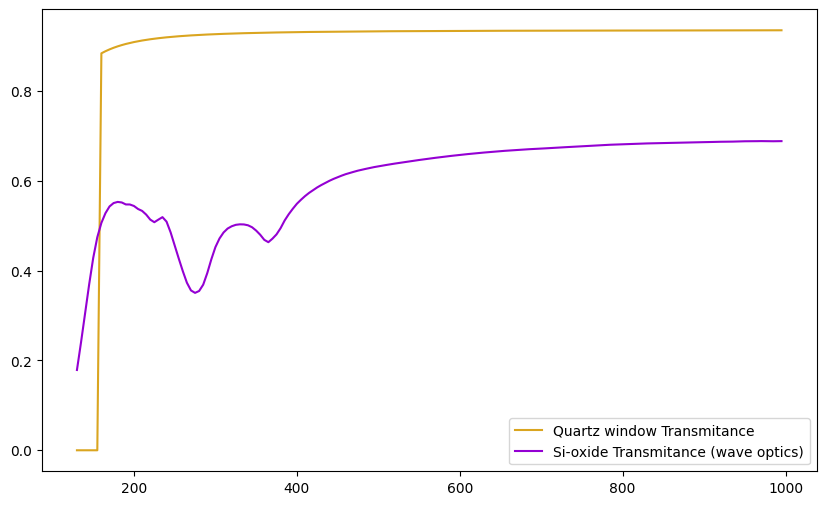

In [19]:
xwlen = np.arange(130, 1000, 5)
# xwlen = [160,180,200,300,380]
ap = PhotonInfo(wlen = xwlen, theta_1=0)
standardPN = PNJunction(tOxide=18.)

Tquartz, Rquartz = ap.T_R_quartzWindow()
Tsi = ap.Wave_TotalTransmission(standardPN)
Rsi = ap.Wave_TotalReflection(standardPN)
Ttotal = ap.T_total_windowAndOxide(standardPN)

# testing result for wave optics
twindow = 0.5 * 1e6 # mm to nm
n1 = ap.nVacuum
n2 = ap.nOxide
theta1=ap.theta_1 # in vacuum
theta2=ap.theta_2 # in quartz
Tquartz_wave = ME.Wave_TwoLayerTransmission_total(xwlen, thick=twindow, n1=n1, n2=n2, n3=n1, theta1=theta1, theta2=theta2, theta3=theta1)
Rquartz_wave = ME.Wave_TwoLayerReflection_total(xwlen, thick=twindow, n1=n1, n2=n2, n3=n1, theta1=theta1, theta2=theta2, theta3=theta1)
Ttotal_wave = Tsi*Tquartz_wave/(1-Rquartz_wave*Rsi)

plt.figure(figsize=(10, 6))

# plt.plot(xwlen, Rquartz, label = "Quartz window full Reflectance")
plt.plot(xwlen, Tquartz, label = "Quartz window Transmitance")

plt.plot(xwlen, Tsi, label = "Si-oxide Transmitance (wave optics)")

# plt.plot(xwlen, Ttotal, label = "Total Transmitance\n(ray optics on window x wave on Si)")

# Ttotal_test = ap.T_total_windowAndOxide(25)
# plt.plot(xwlen, Ttotal_test, label = "Total Transmitance (test, 25nm)")

# plt.plot(xwlen, Ttotal_wave, alpha = 0.3, label = "Total Transmitance (wave optics)")
# plt.plot(xwlen, -0.0 + ap.T_total_windowAndOxide(standardPN), label = "test from photon object")

plt.legend()

# print(xwlen)
# print(Tsi)
print()

---
## PDE Equation
$$ PDE = FF \cdot T \cdot \big( W_p \cdot P_e + W_n \cdot P_h\big)$$
Everything else is as defined above. $P_{e, h}$ are the probabilities that a created electron/hole pair will produce an avalanche.

Transmission is a function of photon and junction:
$$T \rightarrow T(\lambda, \theta_1, PN)$$
$$W \rightarrow W(\theta_3, k_\lambda, PN)$$
The Fill Factor $FF$ is fixed. And the avalanche probabilities will increase monotically with overvoltage $V_{ov}$.
$$P_{e, h} \rightarrow P_{e, h}(V_{ov})$$

including quantum effects
$$ P_e \rightarrow 1 - (1-P_e)^{\eta}$$

---
$$ PDE = FF \cdot T(\lambda, \theta; t_{oxide}) \cdot \big[ W_p(\lambda; dp^*, X_{PN}) \cdot P_e(V) + W_n(\lambda; X_{PN}, dw^*) \cdot P_h(V) \big]$$

temperature scaling not tested/validated below 300nm, be careful
PDE becomes affected by charge carrier freezeout below 150k, photo absorption alone may not be enough.


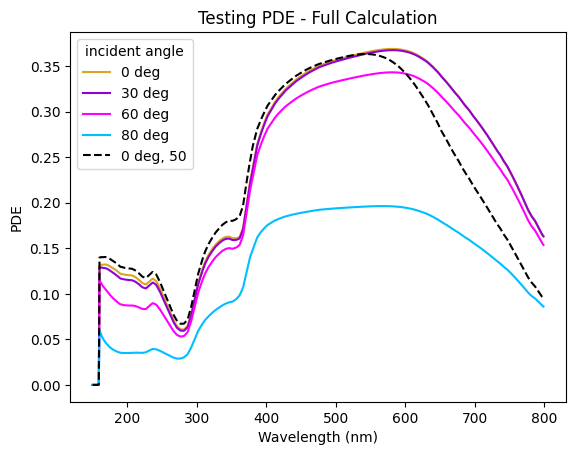

In [20]:
def StandardPDE(FF, T, Wp, Wn, Pe, Ph):
    return FF * T * (Wp*Pe + Wn*Ph)

def FullPDE_fromObjects(PNInfo, PhotonInfo):
    Wp, Wn = PNInfo.calcW_both(PhotonInfo)
    T = PhotonInfo.T_total_windowAndOxide(PNInfo)
    return StandardPDE(FF=PNInfo.FF, T=T, Wp=Wp, Wn=Wn, Pe=PNInfo.pe, Ph=PNInfo.ph)

def InternalPDE_fromObject(PNInfo, PhotonInfo):
    Wp, Wn = PNInfo.calcW_both(PhotonInfo)
    return Wp * PNInfo.pe + Wn * PNInfo.ph

pn = PNJunction(tOxide = 16, dp_star = 5, Xpn = 1200, dw_star = 6500)
pn.pE = 0.99
pn.pH = 0.1
pnDeeper = copy.deepcopy(pn)

pushBack = 10
# pnDeeper.dp_star += pushBack
# pnDeeper.dp += pushBack
# pnDeeper.Xpn += pushBack
# pnDeeper.dw_star += pushBack

xwlen = np.arange(150, 800, 1)
thetaList = [0, 30, 60, 80]

for i, theta in enumerate(thetaList):
    col = ms.allColsStr[i]
    PDE = np.array([FullPDE_fromObjects(pn, PhotonInfo(wlen = wl, theta_1=theta)) for wl in xwlen])
    plt.plot(xwlen, PDE, label=f"{theta:0.0f} deg", color = col)


pdeCold = FullPDE_fromObjects(pn, PhotonInfo(wlen = xwlen, theta_1=0, materialTemp = 50))
plt.plot(xwlen, pdeCold, label=f"0 deg, 50", color = "black", linestyle = "--")

# pdeDeeper = np.array([FullPDE_fromObjects(pnDeeper, PhotonInfo(wlen = wl, theta_1=thetaList[2])) for wl in xwlen])
# plt.plot(xwlen, pdeDeeper, label=f"Deeper dp* +{pushBack}nm,\n{thetaList[2]} deg", color = "black", linestyle = "--")

# plt.xlim(350, 800)
plt.legend(title = "incident angle")
plt.ylabel("PDE")
plt.xlabel("Wavelength (nm)")
plt.title("Testing PDE - Full Calculation")
plt.show()

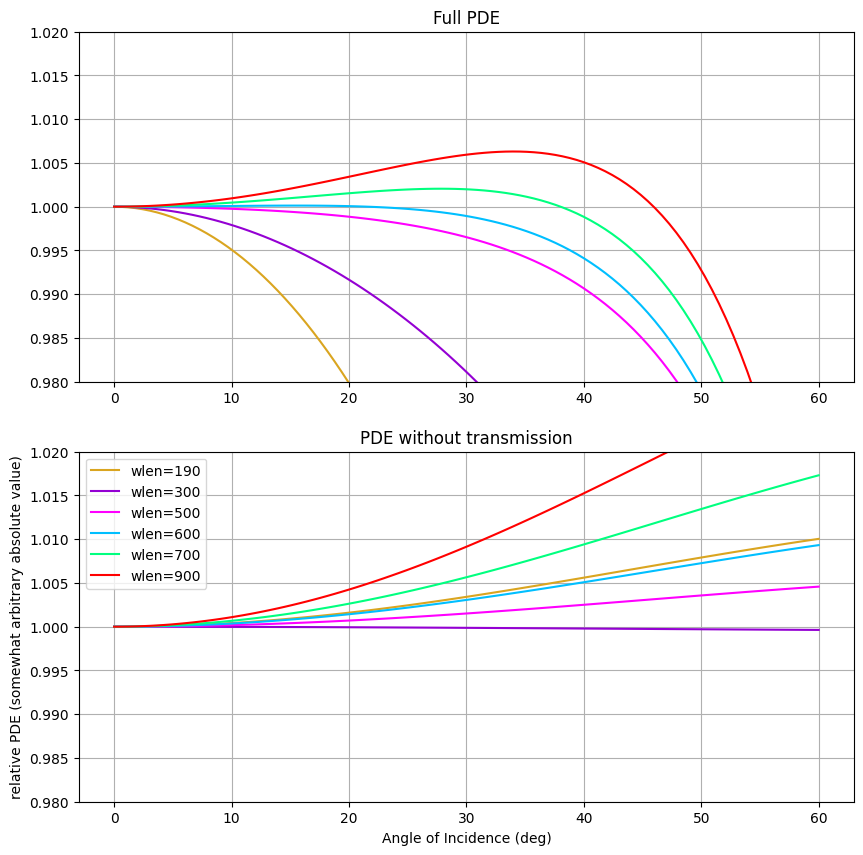

In [21]:
pn = PNJunction(tOxide = 17, dp_star = 1.5, Xpn = 0.8e3, dw_star = 5e3, pe = 1.0, ph = 0.4)
pn2 = PNJunction(tOxide = 17, dp_star = 1.5, Xpn = 0.8e3, dw_star = 3e3, pe = 1.0, ph = 0.4)

xAngles = np.linspace(0, 60, 100)
vlines = [190, 300, 500, 600, 700, 900]
# vlines = [590]
ms.ResetColorCycle()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize = (10, 10))

# complete PDE
ax1.set_title("Full PDE")
for i, wlen in enumerate(vlines):
    col = ms.GetNextColor()
    photon1 = PhotonInfo(wlen = wlen, theta_1=xAngles)
    PDE = np.array(FullPDE_fromObjects(pn, photon1))
    ax1.plot(xAngles, PDE/PDE[0], color = col, label = f"wlen={wlen}") #Xpn:{pn.Xpn/1000} um, dw*:{pn.dw_star/1000} um")
    
    # PDE2 = np.array(FullPDE_fromObjects(pn2, PhotonInfo(wlen = wlen, theta_1=xAngles)))
    # plt.plot(xAngles, PDE2/PDE2[0], color = col, linestyle = "--", label = f"Xpn:{pn2.Xpn/1000} um, dw*:{pn2.dw_star/1000} um")

ms.ResetColorCycle()
ax2.set_title("PDE without transmission")
# PDE with Transmission factored out
for i, wlen in enumerate(vlines):
    col = ms.GetNextColor()
    photon1 = PhotonInfo(wlen = wlen, theta_1=xAngles)
    PDE = np.array(InternalPDE_fromObject(pn, photon1))
    ax2.plot(xAngles, PDE/PDE[0], color = col, label = f"wlen={wlen}") #Xpn:{pn.Xpn/1000} um, dw*:{pn.dw_star/1000} um")

ax1.set_ylim(0.98, 1.02)
ax2.set_ylim(0.98, 1.02)
ax1.grid()
ax2.grid()
plt.xlabel("Angle of Incidence (deg)")
plt.ylabel("relative PDE (somewhat arbitrary absolute value)")
plt.legend(title=f"", fontsize=10)
plt.show()


---
## Testing Vuye PDE at low temp

lower Temp gives more resonant n, k, which increases curviness of the lines. model is already too curvy.
but increased photoabsorption can oppose this effect. lets see what it looks like

-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/si_vuye_300k.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-m

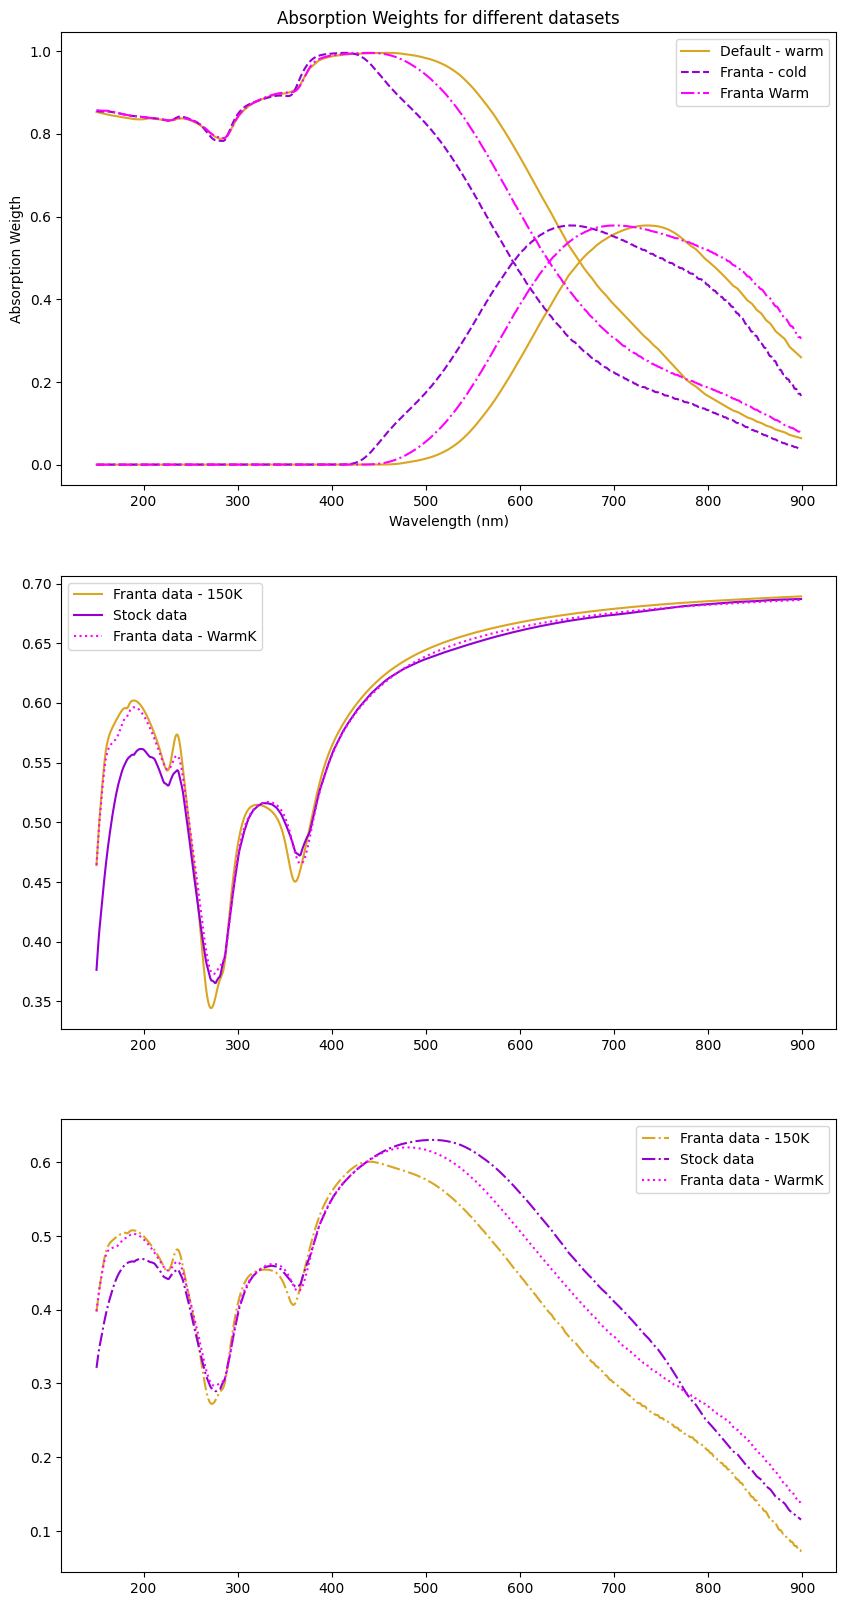

In [22]:
## testing vuye data in vis
xwlen = np.arange(150, 900, 1)
pn = PNJunction(tOxide = 17, dp_star = 1, Xpn = 2.2e3, dw_star = 13e3, pe = 1.0, ph = 0.)

dhStock = OpticsData()
phStock = PhotonInfo(wlen = xwlen, theta_1=0, dataHelper=dhStock, materialTemp = None)
yTransStock = phStock.Wave_TotalTransmission(t_oxideSmall)
WpStock = pn.calcWp(phStock)
WnStock = pn.calcWn(phStock)

dh_vuyeRT = OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "si_vuye_300k.txt"))
phVuyeRT = PhotonInfo(wlen = xwlen, theta_1=0, dataHelper=dh_vuyeRT)
yTransVuyeRT = phVuyeRT.Wave_TotalTransmission(t_oxideSmall)
Wp = pn.calcWp(phVuyeRT)
Wn = pn.calcWn(phVuyeRT)

dh_vuye = OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "temp_extrapolation", "vuye_silicon_extended160K_1dinterp.txt"))
phVuye = PhotonInfo(wlen = xwlen, theta_1=0, dataHelper=dh_vuye)
yTransVuye = phVuye.Wave_TotalTransmission(t_oxideSmall)
Wpcold = pn.calcWp(phVuye)

dh_Franta = OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "Franta_data", "Franta-150K.txt"))
phFranta = PhotonInfo(wlen = xwlen, theta_1=0, dataHelper=dh_Franta)
yTransFranta = phFranta.Wave_TotalTransmission(t_oxideSmall)
WpFranta = pn.calcWp(phFranta)
WnFranta = pn.calcWn(phFranta)

dh_Franta_Warm = OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "Franta_data", "Franta-293K.txt"))
phFranta_Warm = PhotonInfo(wlen = xwlen, theta_1=0, dataHelper=dh_Franta_Warm)
yTransFranta_Warm = phFranta_Warm.Wave_TotalTransmission(t_oxideSmall)
WpFranta_Warm = pn.calcWp(phFranta_Warm)
WnFranta_Warm = pn.calcWn(phFranta_Warm)




ms.ResetColorCycle()

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize = (10, 20))

# ax1.plot(xwlen, Wp, label=f"RT", color = col)
# ax1.plot(xwlen, Wn, color = col, linestyle = "--")

# ax1.plot(xwlen, Wpcold, label=f"cold", color = col, linestyle = "-.")

ax1.plot(xwlen, WpStock, label=f"Default - warm", color = ms.GetNextColor(), linestyle = "-")
ax1.plot(xwlen, WnStock, color = ms.GetNextColor(1), linestyle = "-")

ax1.plot(xwlen, WpFranta, label=f"Franta - cold", color = ms.GetNextColor(), linestyle = "--")
ax1.plot(xwlen, WnFranta, color = ms.GetNextColor(1), linestyle = "--")

ax1.plot(xwlen, WpFranta_Warm, label=f"Franta Warm", color = ms.GetNextColor(), linestyle = "-.")
ax1.plot(xwlen, WnFranta_Warm, color = ms.GetNextColor(1), linestyle = "-.")

ax1.set_xlabel("Wavelength (nm)")
ax1.set_ylabel("Absorption Weigth")
ax1.set_title("Absorption Weights for different datasets")
ax1.legend()

## transmission
# ax2.plot(xwlen, yTransVuyeRT, linestyle = "--", label="Vuye data - 300K")
# ax2.plot(xwlen, yTransVuye, linestyle = "--", label="Vuye data - 160K")
ax2.plot(xwlen, yTransFranta, linestyle = "-", label="Franta data - 150K")
ax2.plot(xwlen, yTransStock, linestyle = "-", label="Stock data")
ax2.plot(xwlen, yTransFranta_Warm, linestyle = ":", label="Franta data - WarmK")
ax2.legend()


## combination
ph = 0.4
# ax3.plot(xwlen, Wp*yTransVuyeRT, linestyle = "-", label="RT")
# ax3.plot(xwlen, Wpcold*yTransVuye, linestyle = "--", label="Vuye data - 160K")
ax3.plot(xwlen, (WpFranta+ph*WnFranta)*yTransFranta, linestyle = "-.", label="Franta data - 150K")
ax3.plot(xwlen, (WpStock+ph*WnStock)*yTransStock, linestyle = "-.", label="Stock data")
ax3.plot(xwlen, (WpFranta_Warm+ph*WnFranta_Warm)*yTransFranta_Warm, linestyle = ":", label="Franta data - WarmK")
ax3.legend()

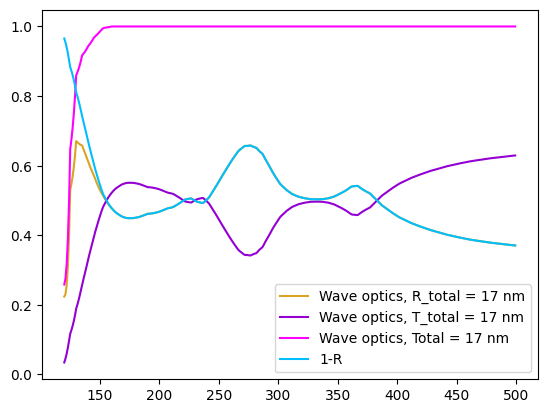

In [23]:
wlens = np.arange(120, 500, 1)

photon = PhotonInfo(wlen = wlens, theta_1=0)

tox = 17

Twave = photon.Wave_TotalReflection(tox)
Rwave = photon.Wave_TotalTransmission(tox)

plt.plot(wlens, Twave, label=f"Wave optics, R_total = {tox} nm")
plt.plot(wlens, Rwave, label=f"Wave optics, T_total = {tox} nm")

plt.plot(wlens, Twave + Rwave, label=f"Wave optics, Total = {tox} nm")
plt.plot(wlens, 1-Rwave, label = "1-R")

plt.legend()

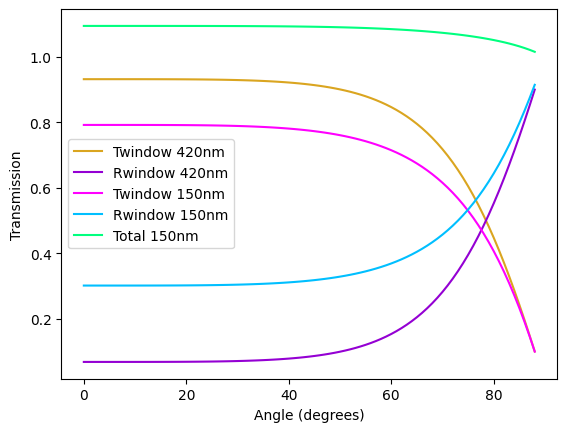

In [24]:
angles = np.arange(0, 89, 1)
photonAng1 = PhotonInfo(wlen = 420, theta_1 = angles)

photonAng2 = PhotonInfo(wlen = 122, theta_1 = angles)

Twindow, Rwindow = photonAng1.T_R_quartzWindow(absorption = False)
Twindow2, Rwindow2 = photonAng2.T_R_quartzWindow(absorption = False)

plt.plot(angles, Twindow, label='Twindow 420nm')
plt.plot(angles, Rwindow, label='Rwindow 420nm')
# plt.plot(angles, Twindow + Rwindow, label='Total 420nm')

plt.plot(angles, Twindow2, label='Twindow 150nm')
plt.plot(angles, Rwindow2, label='Rwindow 150nm')
plt.plot(angles, Twindow2 + Rwindow2, label='Total 150nm')

plt.xlabel('Angle (degrees)')
plt.ylabel('Transmission')
plt.legend()